# SWIFTSimIO/SWIFTGalaxy demo - SWIFTCON 2026

This notebook includes demonstrations of some features that will be released in the coming days. We therefore need to install some packages from github rather than pypi.

In [ ]:
!pip install git+https://github.com/yt-project/unyt.git
!pip install git+https://github.com/SWIFTSIM/swiftsimio.git@a_helper
!pip install git+https://github.com/SWIFTSIM/swiftgalaxy.git@masked-soap
!pip install hdfstream
!pip install matplotlib

In [1]:
import numpy as np
import swiftsimio
import hdfstream

%matplotlib inline

We'll use a SOAP catalogue and snapshot from the FLAMINGO public data release for this example. These can be opened directly without first downloading them, and only the parts of the files actually needed will be streamed to use locally. This is possible using the `hdfstream` package.

In [2]:
sim = hdfstream.open("cosma", "/FLAMINGO/L1_m10/L1_m10/")
snap_file = sim["snapshots/flamingo_0077/flamingo_0077.hdf5"]
soap_file = sim["SOAP-HBT/halo_properties_0077.hdf5"]

Although the files can be accessed directly with `hdfstream`, it's more convenient to load them into `swiftsimio` or `swiftgalaxy` for use. We'll begin by using `swiftsimio` to read part of the SOAP catalogue (a small corner of the box) so that we can find a galaxy to investigate further.

In [3]:
soap_mask = swiftsimio.mask(soap_file)
soap_mask.constrain_spatial([[0.0 * b, 0.05 * b] for b in soap_mask.metadata.boxsize])
soap_catalogue = swiftsimio.load(soap_file, mask=soap_mask)

We can query the catalogue for a galaxy with m200c of about 1e13 Msun. We'll just grab the first eligible galaxy in the list. When defining the mass range, we use a new feature: a helper object that sets cosmological attributes of arrays.

In [4]:
import unyt as u  # package used by swiftsimio to provide physical units

m200c = soap_catalogue.spherical_overdensity_200_crit.total_mass
# we can initialize constants/arrays in comoving units with this:
a_com = (
    soap_catalogue.metadata.a.comoving
)  # could use soap.catalogue.metadata.a.physical
# a.com or a.c are also allowed for comoving, and a.phys and a.p for physical
candidates = np.argwhere(
    np.logical_and(m200c > 5e13 * u.solMass * a_com**0, m200c < 1e14 * u.solMass * a_com**0)
).squeeze()
# If the quantity depends on a power of the scale factor write e.g.:
# `1000 * u.km / u.s * a_com**0`, or `1e19 * u.solMass / u.pc**2 * a_phys**-2`
chosen_halo_index = candidates[0]
print(chosen_halo_index)

180


Now we can create a `SWIFTGalaxy` to experiment with. The `soap_index` selects one row from the halo catalogue. The `SWIFTGalaxy` object will contain all of the integrated properties of this object from the halo catalogue and also let us access its particles from the snapshot file.

In [5]:
from swiftgalaxy import SWIFTGalaxy, SOAP

sg = SWIFTGalaxy(
    snap_file,
    SOAP(
        soap_file,
        soap_index=chosen_halo_index,
        soap_mask=soap_mask,  # required, otherwise our galaxy is picked from the unmasked catalogue!
    ),
)

/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(


## Tab completion

Tab completion is supported, so you can try interactions like `sg.<tab>`, `sg.gas.<tab>`, `sg.gas.element_mass_fractions.<tab>`, `sg.halo_catalogue.<tab>`, `sg.halo_catalogue.spherical_overdensity_200_crit.<tab>` in an interactive session to see all available fields and operations. This should work in IPython, Jupyter and newer Python interpreters. (In some interpreters you may need to press `<tab>` twice.) Because the listing is determined dynamically based on the metadata in the input `hdf5` file, so your IDE most likely cannot offer this tab completion unless it has access to a `SWIFTGalaxy` object actually created from the relevant `hdf5` files.

## Visualisation

`swiftgalaxy` supports the `swiftsimio` visualisation tools. We can use these to make some quick images of this galaxy:

In [6]:
from swiftsimio.visualisation.projection import project_gas, project_pixel_grid
from swiftsimio.visualisation import generate_smoothing_lengths
import matplotlib.pyplot as plt
import matplotlib.colors


def myvis(
    sg: SWIFTGalaxy,
    disc_radius: u.unyt_quantity = 100.0 * u.kpc,
    halo_radius: u.unyt_quantity = 1000.0 * u.kpc,
    fignum: int = 1,
    backend: str = "fast",
) -> None:
    """
    Quickly visualise gas, dark matter and stars in a SWIFTGalaxy.

    Parameters
    ----------
    sg : :class:`~swiftgalaxy.reader.SWIFTGalaxy`
        The galaxy to visualise.

    disc_radius : :class:`~unyt.array.unyt_quantity`
        Nominal size of the disc to set the image side length for gas and stars.

    halo_radius : :class:`~unyt.array.unyt_quantity`
        Nominal size of the halo to set the image side length for dark matter.

    fignum : :obj:`int`
        Figure number to use for :mod:`matplotlib`.

    backend : :obj:`str`
        The visualisation "backend" to use, e.g. ``"fast"``, ``"nested"``, etc.
    """
    # Before visualising the galaxy, we need to initialise some smoothing
    # lengths for the dark matter particles (this bit of code is taken
    # from the `swiftsimio` visualisation documentation).
    if not hasattr(sg.dark_matter, "smoothing_lengths"):
        sg.dark_matter.smoothing_lengths = generate_smoothing_lengths(
            (sg.dark_matter.coordinates + sg.centre) % sg.metadata.boxsize,
            sg.metadata.boxsize,
            kernel_gamma=1.8,
            neighbours=57,
            speedup_fac=2,
            dimension=3,
        )
    a_phys = sg.metadata.a.physical
    disc_region = (
        u.unyt_array([-disc_radius, disc_radius, -disc_radius, disc_radius]) * a_phys
    )
    halo_region = (
        u.unyt_array([-halo_radius, halo_radius, -halo_radius, halo_radius]) * a_phys
    )
    gas_map = project_gas(
        sg,
        resolution=256,
        project="masses",
        parallel=True,
        periodic=False,  # always recommended when using swiftgalaxy
        region=disc_region,
        backend=backend,
    )
    dm_map = project_pixel_grid(
        data=sg.dark_matter,
        resolution=256,
        project="masses",
        parallel=True,
        periodic=False,  # always recommended when using swiftgalaxy
        region=halo_region,
        backend=backend,
    )
    star_map = project_pixel_grid(
        data=sg.stars,
        resolution=256,
        project="masses",
        parallel=True,
        periodic=False,  # always recommended when using swiftgalaxy
        region=disc_region,
        backend=backend,
    )
    fig = plt.figure(fignum, figsize=(10, 3))
    sp1, sp2, sp3 = [fig.add_subplot(1, 3, i) for i in range(1, 4)]
    sp1.imshow(
        matplotlib.colors.LogNorm()(gas_map.to_physical_value(u.solMass / u.kpc**2).T),
        cmap="viridis",
        extent=disc_region,
        origin="lower",
    )
    sp1.set_xlabel(f"x' [{disc_radius.units}]")
    sp1.set_ylabel(f"y' [{disc_radius.units}]")
    sp1.text(
        0.9,
        0.9,
        "gas",
        ha="right",
        va="top",
        color="black",
        backgroundcolor="white",
        transform=sp1.transAxes,
    )
    sp2.imshow(
        matplotlib.colors.LogNorm()(dm_map.to_physical_value(u.solMass / u.kpc**2).T),
        cmap="inferno",
        extent=halo_region,
        origin="lower",
    )
    sp2.plot(
        [-disc_radius, -disc_radius, disc_radius, disc_radius, -disc_radius],
        [-disc_radius, disc_radius, disc_radius, -disc_radius, -disc_radius],
        "-k",
    )
    sp2.set_xlabel(f"x' [{halo_radius.units}]")
    sp2.set_ylabel(f"y' [{halo_radius.units}]")
    sp2.text(
        0.9,
        0.9,
        "DM",
        ha="right",
        va="top",
        color="black",
        backgroundcolor="white",
        transform=sp2.transAxes,
    )
    sp3.imshow(
        matplotlib.colors.LogNorm()(star_map.to_physical_value(u.solMass / u.kpc**2).T),
        cmap="magma",
        extent=disc_region,
        origin="lower",
    )
    sp3.set_xlabel(f"x' [{disc_radius.units}]")
    sp3.set_ylabel(f"y' [{disc_radius.units}]")
    sp3.text(
        0.9,
        0.9,
        "stars",
        ha="right",
        va="top",
        color="black",
        backgroundcolor="white",
        transform=sp3.transAxes,
    )
    sp2.set_title(f"soap_index={sg.halo_catalogue.soap_index}")
    fig.subplots_adjust(wspace=0.4)

Let's have a first look at our galaxy:

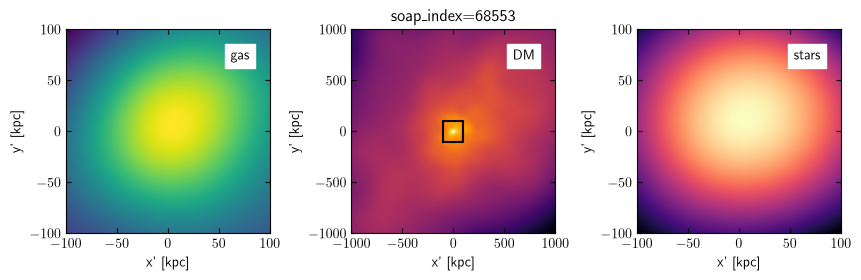

In [7]:
myvis(sg)

## Quick overview of `swiftgalaxy` features

### `SWIFTDataset` features

`SWIFTGalaxy` is built upon `swiftsimio` and takes advantage of all the features of the `SWIFTDataset` class, notably "lazy loading" of particle data. A `SWIFTGalaxy` inherits from the `SWIFTDataset` class, and should therefore in principle be accepted by functions expecting a `SWIFTDataset`.

### SOAP integrated properties

A `swiftsimio` interface to the SOAP halo catalogue is exposed through the `halo_catalogue` attribute of our `SWIFTGalaxy`, and only the properties of the particular galaxy of interest are loaded. This makes accessing integrated properties particularly convenient, for instance we can access M200crit:

In [8]:
sg.halo_catalogue.spherical_overdensity_200_crit.total_mass.to(u.Msun)

cosmo_array([6.768e+13], dtype=float32, units='1.98841586e+30*kg', comoving='False', cosmo_factor='1 at a=1.0', valid_transform='True')

Notice that this result has one more dimension than you might have been expecting (so the "scalar" mass is here an array with dimension `(1,)`, a 3-element array of coordinates would be a `(1,3)` array, etc.). This is for consistency with reading in a "full" SOAP catalogue. You may wish to use `.squeeze()` on the result to remove any dimensions of size `1`.

### Automatic recentering

When the `SWIFTGalaxy` is created, the coordinates are automatically centred on the position and velocity (according to the halo finder) of the galaxy of interest. The SOAP catalogue actually contains many centres and velocities defined in different ways for each halo; which one to use is configurable. The automatic recentering can also be disabled entirely, or the centre of another `SWIFTGalaxy` can be used (can be useful e.g. for putting a satellite in the coordinate frame of its central).

### Rotation & other coordinate transformations

The particles in a `SWIFTGalaxy` always occupy a common coordinate frame, such that e.g. all particles rotate together. Rotations, translations (in position) and boosts (translations in velocity) are all supported. As an example, we can rotate our galaxy. To specify a rotation, the [`scipy.spatial.transform.Rotation`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_euler.html) class is used. This has options to accept rotation matrices, Euler angles, and more. The SOAP catalogue helpfully has pre-computed angular momentum vectors for particles of different types selected in different apertures. Let's use one of these to define a rotation matrix and rotate the stars to a face-on view.

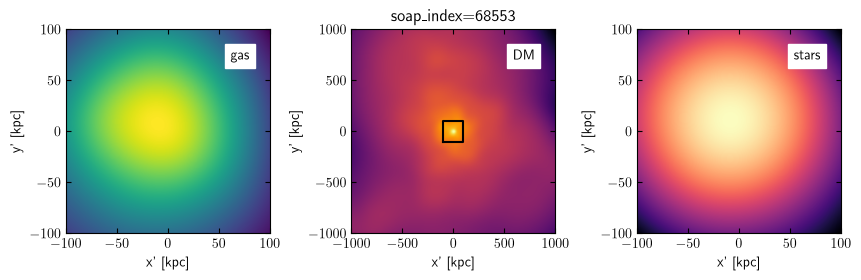

In [9]:
from scipy.spatial.transform import Rotation

Lstars = sg.halo_catalogue.exclusive_sphere_50kpc.angular_momentum_stars.squeeze()
zhat = (Lstars / np.sqrt(np.sum(Lstars**2))).to_physical_value(
    u.dimensionless
)  # we'll align L with the z-axis
arb = (
    np.ones(3) / np.sqrt(3)
)  # we have one degree of freedom, we'll fix it by projecting onto an arbitrarily chosen vector
xvec = arb - arb.dot(zhat) * zhat
xhat = xvec / np.sqrt(np.sum(xvec**2))
yhat = np.cross(zhat, xhat)  # orthogonal, right-handed and normalized
rotmat = np.vstack((xhat, yhat, zhat)).T
sg.rotate(Rotation.from_matrix(rotmat))
myvis(sg)

### Additional coordinates

When working with a galaxy it is often convenient to work in spherical or cylindircal coordinates. These are built into a `SWIFTGalaxy` and are evaluated lazily as and when needed. Their consistency when the coordinate frame is transformed is also ensured. As an illustrative example, we can plot the azimuthal velocity against the radial velocity - the parameters in which the Gaia-Enceladus (or "sausage") structure in the Milky Way was identified. This quick look won't reveal anything quite so profound but illustrates how easy it is to use non-cartesian coordinates.

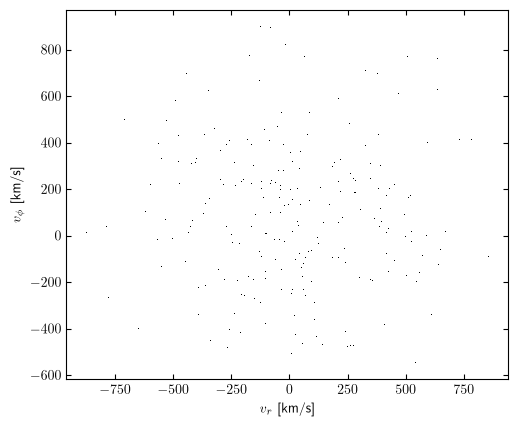

In [10]:
plt.plot(
    sg.stars.spherical_velocities.r.to_physical_value(u.km / u.s),
    sg.stars.spherical_velocities.phi.to_physical_value(u.km / u.s),
    ",k",
    rasterized=True,
)
plt.xlabel(r"$v_r$ [km/s]")
plt.ylabel(r"$v_\phi$ [km/s]")
plt.gca().set_aspect("equal")

### Particle masking

`SWIFTGalaxy` enables selecting subsets of particles in intuitive, syntactically simply ways (beyond what's supported by `swiftsimio`, actually). As a crude example, we can chop a hole out of the centre of the stellar and gas discs. Masking on any other property (gas of a given temperature, stars of a given age, etc.) is also possible, of course.

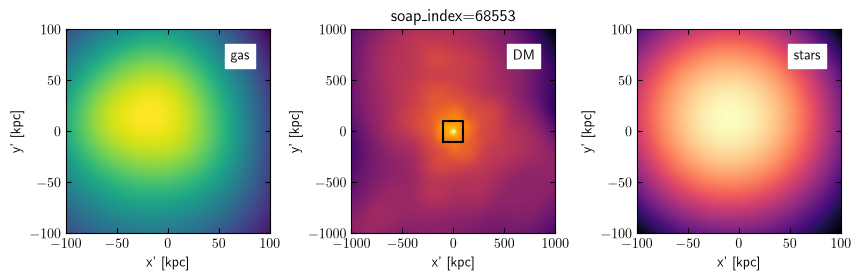

In [11]:
from swiftgalaxy import MaskCollection

sg.mask_particles(
    MaskCollection(
        gas=sg.gas.cylindrical_coordinates.R > 10 * u.kpc * a_com,
        stars=sg.stars.cylindrical_coordinates.R > 10 * u.kpc * a_com,
    )
)
myvis(sg)

The mask applies to all particle properties, e.g. if we next loaded the gas temperatures they would be masked to match. It's also possible to obtain masked particle datasets with `sg.gas[...]` (careful, unlike using `sg.mask_particles` these are copies, so memory consumption can increase quickly), amongst other options.

## Efficient iteration over galaxies

The `SWIFTGalaxy` demonstrated above offers a nice interface, but if looking at many galaxies using it adds substantial overhead (mostly duplicated I/O if any of the galaxies are spatially close together). The `SWIFTGalaxies` class enables efficient iteration over `SWIFTGalaxy` objects.

Up above we gathered a list of candidate targets. Instead of looking only at the first one, let's iterate over the first 5 for this demo.

We can use the `SWIFTGalaxies` (not `SWIFTGalaxy`) class to help us iterate over these. This class offers most of the same options as the `SWIFTGalaxy` class, but expects a `SOAP` object with a `list` of targets passed to `soap_index` instead of a single integer. The `SWIFTGalaxies` class will figure out an efficient iteration strategy to minimize I/O.

**Very important**: the iteration does not necessarily happen in the order that the `soap_index` list is given! The most efficient order is determined by `SWIFTGalaxies`. To obtain results in a list matching the input order, use the `map` method (see further below).

Iterating over galaxies [180 181 200 433]


/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(
/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(
/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding

SWIFTGalaxy at /FLAMINGO/L1_m10/L1_m10/snapshots/flamingo_0077/flamingo_0077.hdf5.
SWIFTGalaxy at /FLAMINGO/L1_m10/L1_m10/snapshots/flamingo_0077/flamingo_0077.hdf5.


/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(


SWIFTGalaxy at /FLAMINGO/L1_m10/L1_m10/snapshots/flamingo_0077/flamingo_0077.hdf5.


/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(


SWIFTGalaxy at /FLAMINGO/L1_m10/L1_m10/snapshots/flamingo_0077/flamingo_0077.hdf5.


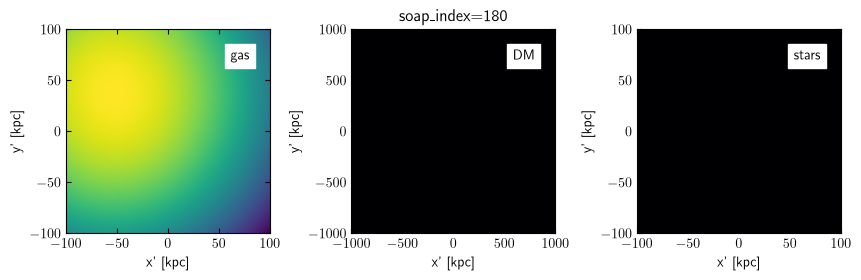

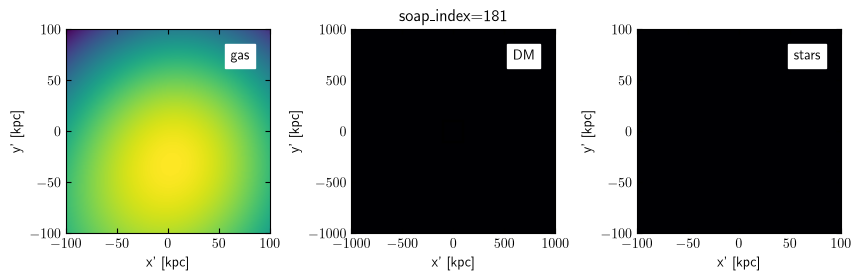

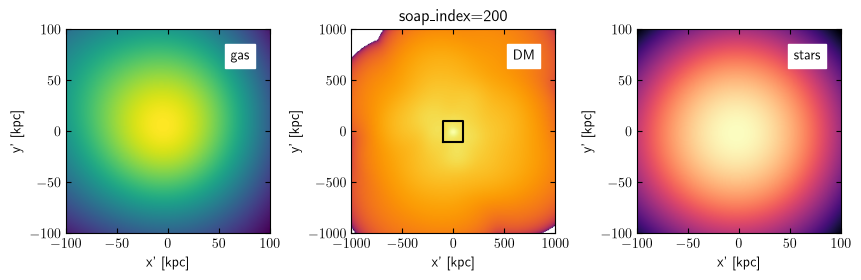

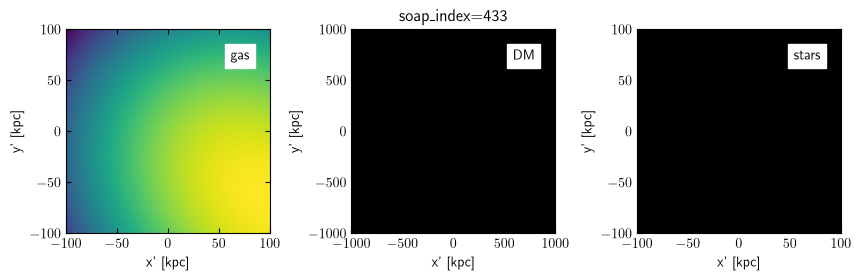

In [12]:
from swiftgalaxy.iterator import SWIFTGalaxies

soap_indices = candidates[:5]  # grab 5 objects from our list of targets

print(f"Iterating over galaxies {soap_indices}")

figcounter = 2
for sg in SWIFTGalaxies(
    snap_file,
    SOAP(
        soap_file,
        soap_index=soap_indices,
    ),
):
    print(sg)
    myvis(sg, fignum=figcounter)
    figcounter += 1

In this case the figures have (probably) appeared in the same order as the list of input targets, but we can consider this luck.

We can instead guarantee getting ordered results using the `map` method:

/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(
/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding region by 0.1 times cell length to account for drifted particles. This behaviour can be configured/disabled with the `safe_padding` parameter when creating the mask. See https://swiftsimio.readthedocs.io/en/latest/masking/index.html for further details.
  warnings.warn(
/home/txwx36/code/swiftsimio/swiftsimio/masks.py:366: UserWarning: Snapshot does not contain Cells/MinPositions and Cells/MaxPositions metadata. Padding

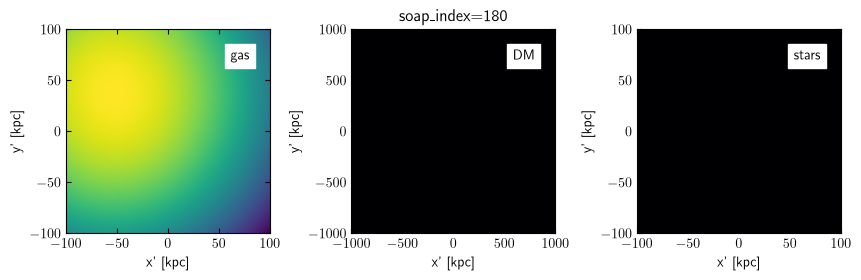

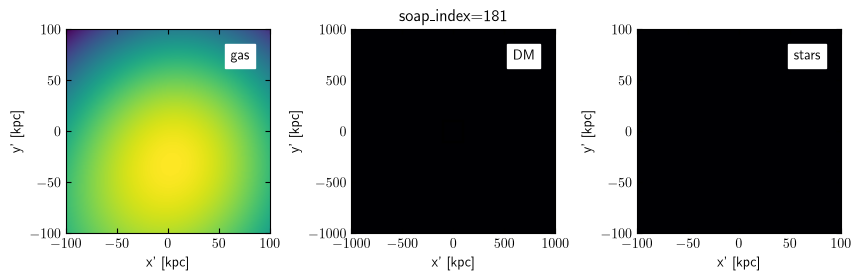

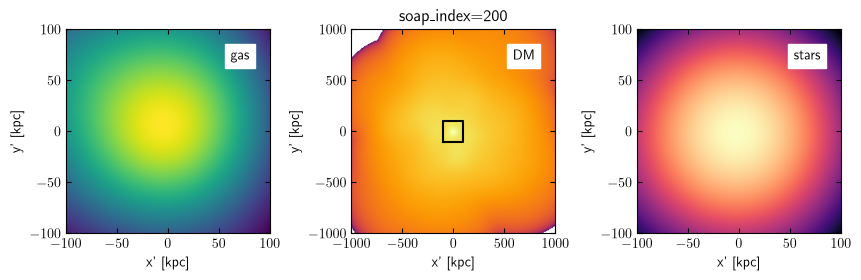

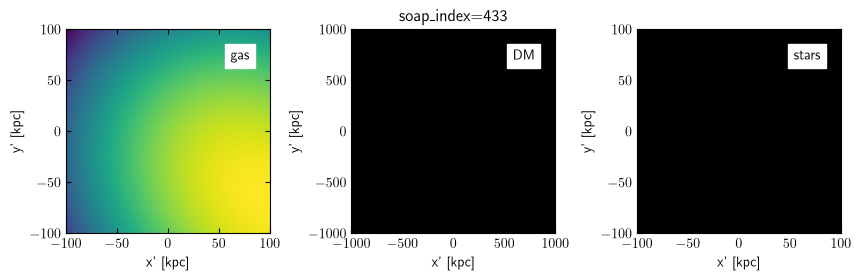

In [13]:
# we've used figs 1-6 above, continue from there:
output_fignums = [{"fignum": fig_i} for fig_i in range(7, 12)]
sgs = SWIFTGalaxies(
    snap_file,
    SOAP(
        soap_file,
        soap_index=soap_indices,
    ),
)
# Use map to apply `myvis` to each `sg` in `sgs` and give us the results
# in order.
output_figures = sgs.map(myvis, kwargs=output_fignums)

The figures *could* still appear out of order in this notebook because, just to keep things "interesting", they appear in the order that they are created (the optimal order of iteration determined by `SWIFTGalaxies`), but the results *are* ordered correctly in `output_figures`.

If running these examples seems a bit slow, it's because most of the time is spent calculating smoothing lengths, everything else happening actually runs pretty quickly.

A final remark on the `SWIFTGalaxies` class: it seems obvious that one might want to split up the work of iterating over a large number of galaxies to multiple processors. Support for easy parallelization in both multiprocessing- and MPI-style modes will be coming in a future release (yes I said this last year...)!

### Documentation

Detailed documentation for `swiftgalaxy` including descriptions of more options and more detailed explanations of features is [hosted on readthedocs](https://swiftgalaxy.readthedocs.io/en/latest/halo_finders/index.html). Any feedback on the code or documentation is very welcome by email (kyle.a.oman@durham.ac.uk), on Slack, or through an issue on the SWIFTGalaxy [github repository](https://github.com/SWIFTSIM/swiftgalaxy).